In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [ ]:
corpus = ["apple banana fruit", "banana apple fruit", "banana fruit apple",
                 "dog cat animal", "cat animal dog", "cat dog animal"]

In [3]:
corpus = [sent.split(" ") for sent in corpus]
corpus

[['apple', 'banana', 'fruit'],
 ['banana', 'apple', 'fruit'],
 ['banana', 'fruit', 'apple'],
 ['dog', 'cat', 'animal'],
 ['cat', 'animal', 'dog'],
 ['cat', 'dog', 'animal']]

In [4]:
flatten = lambda l: [item for sublist in l for item in sublist]
vocab = list(set(flatten(corpus)))
vocab

['apple', 'banana', 'animal', 'dog', 'fruit', 'cat']

In [5]:
word2indx = {v : indx for indx , v in enumerate(vocab)}
word2indx

{'apple': 0, 'banana': 1, 'animal': 2, 'dog': 3, 'fruit': 4, 'cat': 5}

In [6]:
indx2word = {indx : v for indx , v in enumerate(vocab)}
indx2word

{0: 'apple', 1: 'banana', 2: 'animal', 3: 'dog', 4: 'fruit', 5: 'cat'}

In [7]:
vocab.append("<UNK>")
word2indx["<UNK>"] = 6
indx2word[6] = "<UNK>"

In [8]:
def Random_batch(batch_size,corpus):
    skipgram = []
    for doc in corpus:
        for i in range(1,len(doc)-1):
            center = word2indx[doc[i]]
            outside = (word2indx[doc[i-1]],word2indx[doc[i+1]])
            for each_outside in outside:
                skipgram.append([center,each_outside])
    random_index = np.random.choice(range(len(skipgram)),batch_size,replace = False)
    inputs,label = [],[]
    for indx in random_index:
        inputs.append([skipgram[indx][0]])
        label.append([skipgram[indx][1]])
    return np.array(inputs),np.array(label)

In [9]:
x,y=Random_batch(2,corpus)

In [10]:
print(x.shape,y.shape)

(2, 1) (2, 1)


In [11]:
class skipgram(nn.Module):
    def __init__(self,vocab_size,emb_size):
        super(skipgram,self).__init__()
        self.embedding_center = nn.Embedding(vocab_size,emb_size)
        self.embedding_outside = nn.Embedding(vocab_size,emb_size)
    def forward(self,center,outside,vocab):
        center_embedding = self.embedding_center(center)
        outside_embedding = self.embedding_outside(outside)
        all_embedding = self.embedding_outside(vocab)

        top_term = torch.exp(outside_embedding.bmm(center_embedding.transpose(1,2)).squeeze(2))
        lower_term = torch.exp(all_embedding.bmm(center_embedding.transpose(1,2)).squeeze(2))
        lower_term_sum = torch.sum(lower_term,1,keepdim=True)
        loss = -torch.mean(torch.log(top_term / lower_term_sum))
        
        
        return loss
        

In [12]:
batch_size = 2
vocab_size = len(vocab)
def prepare_seq(seq,word2indx):
    indx = list(map(lambda w : word2indx[w] if word2indx.get(w) is not None else word2indx["<UNK>"],seq))
    return torch.LongTensor(indx)
all_vocab = prepare_seq(list(vocab),word2indx).expand(batch_size,vocab_size)
all_vocab

tensor([[0, 1, 2, 3, 4, 5, 6],
        [0, 1, 2, 3, 4, 5, 6]])

In [13]:
model = skipgram(vocab_size,2)
model

skipgram(
  (embedding_center): Embedding(7, 2)
  (embedding_outside): Embedding(7, 2)
)

In [14]:
input_tensor = torch.LongTensor(x)
label_tensor = torch.LongTensor(y)


In [15]:
loss = model(input_tensor,label_tensor,all_vocab)
loss

tensor(1.2817, grad_fn=<NegBackward0>)

In [16]:
batch_size = 2
emb_size = 2
model =  skipgram(vocab_size,emb_size)
optimizer = optim.Adam(model.parameters(),lr = 0.001)

In [17]:
num_epoch = 5000
for epoch in range(num_epoch):
    input_batch , label_batch = Random_batch(batch_size,corpus)
    input_tensor = torch.LongTensor(input_batch) 
    label_tensor = torch.LongTensor(label_batch)

    loss = model(input_tensor,label_tensor,all_vocab)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if(epoch+1) % 1000 ==0:
        print(f"Epoch {epoch+1} | Loss {loss:2.6f}")



Epoch 1000 | Loss 1.910148
Epoch 2000 | Loss 1.337163
Epoch 3000 | Loss 1.473362
Epoch 4000 | Loss 0.753383
Epoch 5000 | Loss 0.722398


In [19]:
vocab

['apple', 'banana', 'animal', 'dog', 'fruit', 'cat', '<UNK>']

In [21]:
banana = torch.LongTensor([word2indx["banana"]])
banana

tensor([1])

In [24]:
def GetEmbedding(word):
    word2tensor = torch.LongTensor([word2indx[word]]) if word in word2indx else torch.LongTensor([word2indx["<UNK>"]])
    word_embedding = (model.embedding_center(word2tensor) + model.embedding_outside(word2tensor)) / 2
    return word_embedding[0][0].item() ,word_embedding[0][1].item() 

In [25]:
GetEmbedding("dog")

(-0.6643947958946228, -2.3149590492248535)

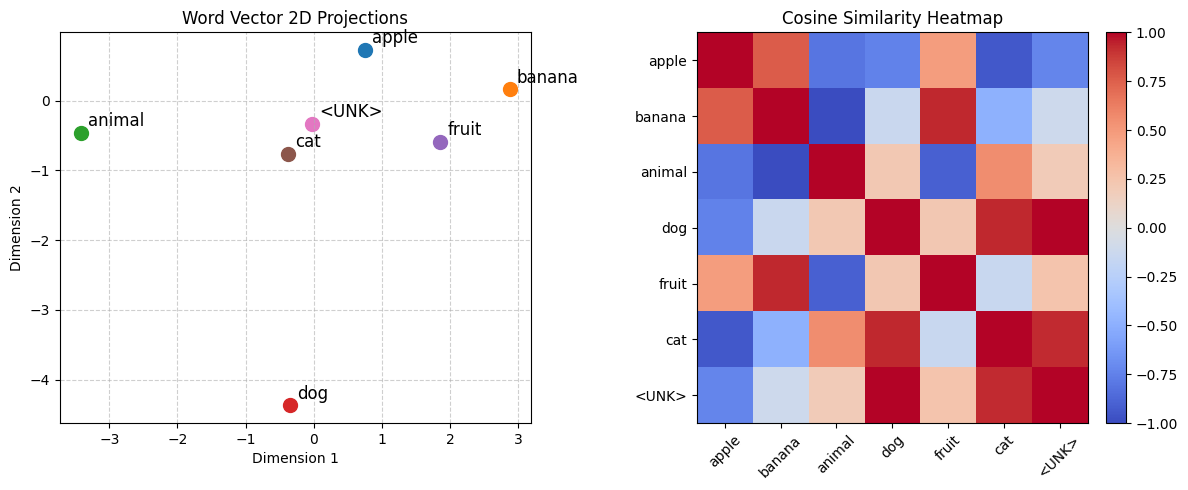

In [26]:
# Extract the trained word vectors from the model's center embeddings
trained_embeddings = model.embedding_center.weight.data.numpy()

# 1. Plot the 2D Scatter Plot of Embeddings
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
for i, w in enumerate(vocab):
    x_val, y_val = trained_embeddings[i, 0], trained_embeddings[i, 1]
    plt.scatter(x_val, y_val, s=100)
    plt.annotate(w, xy=(x_val, y_val), xytext=(5, 2), textcoords='offset points', ha='left', va='bottom', fontsize=12)
plt.title("Word Vector 2D Projections")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.grid(True, linestyle='--', alpha=0.6)

# 2. Compute and Plot Pairwise Cosine Similarity
# Add small epsilon to avoid division by zero
norms = np.linalg.norm(trained_embeddings, axis=1, keepdims=True)
norms = np.where(norms == 0, 1e-9, norms)
norm_embeddings = trained_embeddings / norms
cosine_sim_matrix = np.dot(norm_embeddings, norm_embeddings.T)

plt.subplot(1, 2, 2)
im = plt.imshow(cosine_sim_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(vocab)), vocab, rotation=45, fontsize=10)
plt.yticks(range(len(vocab)), vocab, fontsize=10)
plt.title("Cosine Similarity Heatmap")
plt.tight_layout()
plt.show()
